In [2]:
from google.colab import files

# Prompt to upload a file
uploaded = files.upload()


Saving Final_Dataset_AIBD.csv.gz to Final_Dataset_AIBD.csv (1).gz


In [3]:
import pandas as pd
df = pd.read_csv('/content/Final_Dataset_AIBD.csv.gz')
df
df = df.rename(columns={'Unnamed: 0': 'Name'})
df = df.drop(columns=['Unnamed: 0.1']).rename(columns={'Unnamed: 0': 'Name'})
df

/tmp/ipykernel_356/251196906.py:2: DtypeWarning: Columns (4) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('/content/Final_Dataset_AIBD.csv.gz')


,Name,Age,Gender,ICU,RUNDC3A,DEPDC1,BICDL1,ATP5PB,COTL1,TRIM40,...,CCR1,DMTN,CAVIN2,IZUMO4,SEPTIN10,ZCWPW1,DENND4C,TBX3,SCD5,H2AP
0,C1,39,male,no,0.410000,0.290000,3.500000,83.130000,793.950000,0.130000,...,464.730000,24.290000,55.980000,1.790000,1.930000,2.260000,10.800000,0.000000,0.890000,0.0
1,C2,63,male,no,0.380000,0.930000,4.370000,94.440000,990.270000,1.030000,...,177.660000,35.440000,99.140000,1.740000,1.690000,2.610000,6.190000,0.000000,1.130000,0.0
2,C3,33,male,no,0.390000,0.100000,2.240000,41.240000,719.210000,0.000000,...,393.770000,6.810000,12.310000,1.860000,0.380000,6.120000,3.590000,0.000000,0.620000,0.0
3,C4,49,male,no,0.560000,0.190000,7.870000,123.220000,804.480000,0.300000,...,256.230000,24.500000,122.510000,3.430000,1.820000,5.010000,9.480000,0.010000,1.590000,0.0
4,C5,49,male,no,0.450000,0.440000,1.920000,72.720000,505.980000,0.120000,...,482.630000,15.100000,44.620000,0.510000,0.210000,3.150000,4.390000,0.000000,0.650000,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
180,NC81,18,male,NaN,2.535697,0.023387,1.061867,68.486990,878.511376,0.402942,...,7.195875,18.339219,6.031346,4.281002,0.410692,2.368973,0.392739,0.000254,0.091454,0.0
181,NC82,15,male,NaN,0.890256,0.032683,7.413428,65.070772,1311.710166,0.045746,...,71.612906,13.833811,29.663119,1.689109,0.852816,4.191334,2.895935,0.000254,0.917859,0.0
182,NC83,16,female,NaN,1.307012,0.023387,3.190243,50.016863,1346.659513,0.135118,...,95.839170,19.880872,13.036078,1.895986,1.193758,4.573771,1.575842,0.000254,0.158958,0.0
183,NC84,14,male,NaN,1.138351,0.106631,9.613936,52.493368,1060.417768,0.045746,...,41.763646,14.206949,25.061025,1.858951,0.404773,5.072356,2.224795,0.000254,0.500736,0.0


### Removing Noise
Here, we are removing the columns which show a TPM<1 more than 85% of the time, which would cause the BIC model to overfit on this data.

In [4]:
# 1. Separate metadata columns from gene expression columns
meta_cols = ['Name', 'Age', 'Gender', 'ICU']
gene_cols = [col for col in df.columns if col not in meta_cols]

# 2. Keep gene columns where > 1 occurs in at least 15% of samples (28 rows)
min_samples = 0.15 * len(df)  # Evaluates to 27.75 (requires >= 28 samples)
valid_genes = df[gene_cols].columns[(df[gene_cols] > 1).sum() >= min_samples]

# 3. Combine metadata and filtered gene columns back together
df = pd.concat([df[meta_cols], df[valid_genes]], axis=1)

print(f"Remaining columns: {df.shape[1]}")
df

Remaining columns: 11241


,Name,Age,Gender,ICU,RUNDC3A,BICDL1,ATP5PB,COTL1,AREL1,DNHD1,...,SENP7,SLC6A12,CCR1,DMTN,CAVIN2,IZUMO4,SEPTIN10,ZCWPW1,DENND4C,SCD5
0,C1,39,male,no,0.410000,3.500000,83.130000,793.950000,30.100000,1.690000,...,12.940000,9.150000,464.730000,24.290000,55.980000,1.790000,1.930000,2.260000,10.800000,0.890000
1,C2,63,male,no,0.380000,4.370000,94.440000,990.270000,28.020000,1.090000,...,12.190000,8.000000,177.660000,35.440000,99.140000,1.740000,1.690000,2.610000,6.190000,1.130000
2,C3,33,male,no,0.390000,2.240000,41.240000,719.210000,22.510000,0.660000,...,9.030000,4.550000,393.770000,6.810000,12.310000,1.860000,0.380000,6.120000,3.590000,0.620000
3,C4,49,male,no,0.560000,7.870000,123.220000,804.480000,30.870000,1.860000,...,20.140000,1.420000,256.230000,24.500000,122.510000,3.430000,1.820000,5.010000,9.480000,1.590000
4,C5,49,male,no,0.450000,1.920000,72.720000,505.980000,28.350000,0.640000,...,12.680000,3.690000,482.630000,15.100000,44.620000,0.510000,0.210000,3.150000,4.390000,0.650000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
180,NC81,18,male,NaN,2.535697,1.061867,68.486990,878.511376,3.090786,0.361869,...,2.065249,0.949291,7.195875,18.339219,6.031346,4.281002,0.410692,2.368973,0.392739,0.091454
181,NC82,15,male,NaN,0.890256,7.413428,65.070772,1311.710166,16.332972,0.767018,...,6.320784,2.765214,71.612906,13.833811,29.663119,1.689109,0.852816,4.191334,2.895935,0.917859
182,NC83,16,female,NaN,1.307012,3.190243,50.016863,1346.659513,12.164265,0.693466,...,4.250380,3.037447,95.839170,19.880872,13.036078,1.895986,1.193758,4.573771,1.575842,0.158958
183,NC84,14,male,NaN,1.138351,9.613936,52.493368,1060.417768,19.101866,1.035394,...,4.911542,1.549934,41.763646,14.206949,25.061025,1.858951,0.404773,5.072356,2.224795,0.500736


Applying LogNorm to the complete Dataset

In [5]:
import numpy as np

# 1. Identify gene expression columns (excluding metadata)
meta_cols = ['Name', 'Age', 'Gender', 'ICU']
gene_cols = [col for col in df.columns if col not in meta_cols]

# 2. Apply log2(1 + TPM) transformation
df[gene_cols] = np.log2(1 + df[gene_cols])

df

/usr/local/lib/python3.13/dist-packages/pandas/core/internals/blocks.py:393: RuntimeWarning: invalid value encountered in log2
  result = func(self.values, **kwargs)


,Name,Age,Gender,ICU,RUNDC3A,BICDL1,ATP5PB,COTL1,AREL1,DNHD1,...,SENP7,SLC6A12,CCR1,DMTN,CAVIN2,IZUMO4,SEPTIN10,ZCWPW1,DENND4C,SCD5
0,C1,39,male,no,0.495695,2.169925,6.394548,9.634720,4.958843,1.427606,...,3.801159,3.343408,8.863350,4.660495,5.832384,1.480265,1.550901,1.704872,3.560715,0.918386
1,C2,63,male,no,0.464668,2.424922,6.576522,9.953134,4.858976,1.063503,...,3.721373,3.169925,7.481073,5.187451,6.645875,1.454176,1.427606,1.851999,2.845992,1.090853
2,C3,33,male,no,0.475085,1.695994,5.400538,9.492274,4.555203,0.731183,...,3.326250,2.472488,8.624869,2.965323,3.734439,1.516015,0.464668,2.831877,2.198494,0.695994
3,C4,49,male,no,0.641546,3.148934,6.956754,9.653705,4.994127,1.516015,...,4.401903,1.275007,8.006915,4.672425,6.948484,2.147307,1.495695,2.587365,3.389567,1.372952
4,C5,49,male,no,0.536053,1.545968,6.203984,8.985785,4.875289,0.713696,...,3.773996,2.229588,8.917760,4.008989,5.511595,0.594549,0.275007,2.053111,2.430285,0.722466
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
180,NC81,18,male,NaN,1.821995,1.043951,6.118671,9.780558,2.032378,0.445588,...,1.616004,0.962949,3.034898,4.273458,2.813801,2.400812,0.496403,1.752309,0.477925,0.126251
181,NC82,15,male,NaN,0.918582,3.072694,6.045940,10.358333,4.115447,0.821317,...,2.871998,1.912732,6.182154,3.890817,4.938433,1.427128,0.889719,2.376105,1.961970,0.939496
182,NC83,16,female,NaN,1.206026,2.067034,5.672902,10.396240,3.718555,0.759979,...,2.392422,2.013443,6.597519,4.384110,3.811068,1.534055,1.133404,2.478654,1.365044,0.212828
183,NC84,14,male,NaN,1.096499,3.407888,5.741288,10.051777,4.329258,1.025308,...,2.563535,1.350460,5.418313,3.926659,4.703822,1.515486,0.490337,2.602256,1.689208,0.585670


##Z-Score Normalization
We apply z-scoring to the log normalized dataset and not directly to the original dataset because z-scoring is a linear shift that leaves extreme transcriptomic outliers and right skewness intact, which breaks BIC's Gaussian likelihood assumptions. Log Normalization first compresses extreme expression spikes into symmetric, biologically meaningful changes so that z-scoring can equalize the scale across genes.

We apply z-scoring after the data is split into training data and testing data in order to prevent data leakage.

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Extract the class label from 'Name' (e.g., 'C1' -> 'C', 'NC81' -> 'NC')
# Adjust this if you are stratifying on a different target column
y = df['Name'].str.extract(r'^([A-Za-z]+)', expand=False)

# 2. Perform an 80:20 stratified split with random_state=42
train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    stratify=y,
    random_state=42
)

# Make explicit copies to avoid SettingWithCopyWarning
train_df = train_df.copy()
test_df = test_df.copy()

# 3. Identify gene columns (excluding metadata)
meta_cols = ['Name', 'Age', 'Gender', 'ICU']
gene_cols = [col for col in df.columns if col not in meta_cols]

# 4. Fit StandardScaler ONLY on the training set, then transform both
scaler = StandardScaler()
train_df[gene_cols] = scaler.fit_transform(train_df[gene_cols])
test_df[gene_cols] = scaler.transform(test_df[gene_cols])

print(f"Train shape: {train_df.shape}, Test shape: {test_df.shape}")

Train shape: (148, 11241), Test shape: (37, 11241)


In [7]:
train_df = train_df.sort_values(by='Name').reset_index(drop=True)
test_df = test_df.sort_values(by='Name').reset_index(drop=True)

In [8]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate

# 1. Prepare features (X_train) and binary target (y_train: 1 = Covid 'C', 0 = Non-Covid 'NC')
meta_cols = ['Name', 'Age', 'Gender', 'ICU']
gene_cols = [col for col in train_df.columns if col not in meta_cols]

# Fill any residual NaNs from log2 transformation with 0 (the z-score mean) so liblinear doesn't error out
X_train = train_df[gene_cols].fillna(0)
y_train = (~train_df['Name'].str.startswith('NC')).astype(int)  # 1 if 'C...', 0 if 'NC...'

# 2. Define the 5-fold Stratified CV and the 60-value logarithmic C grid
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
C_grid = np.logspace(-3, 1, 60)

# 3. Evaluate inner 5-fold CV for both log-loss and AUROC across all 60 C values
results = []
for c_val in C_grid:
    clf = LogisticRegression(
        penalty='l1',
        C=c_val,
        solver='liblinear',
        max_iter=2000,
        random_state=42
    )
    scores = cross_validate(
        clf,
        X_train,
        y_train,
        cv=cv,
        scoring=['neg_log_loss', 'roc_auc'],
        n_jobs=-1
    )
    results.append({
        'C': c_val,
        'mean_log_loss': -scores['test_neg_log_loss'].mean(),
        'mean_auroc': scores['test_roc_auc'].mean()
    })

cv_results_df = pd.DataFrame(results)

# 4. Identify and log the best C values for each metric
best_logloss_row = cv_results_df.loc[cv_results_df['mean_log_loss'].idxmin()]
best_auroc_row = cv_results_df.loc[cv_results_df['mean_auroc'].idxmax()]

print(f"Best C by Log-Loss : {best_logloss_row['C']:.6f} (Log-Loss = {best_logloss_row['mean_log_loss']:.4f}, AUROC = {best_logloss_row['mean_auroc']:.4f})")
print(f"Best C by AUROC    : {best_auroc_row['C']:.6f} (AUROC = {best_auroc_row['mean_auroc']:.4f}, Log-Loss = {best_auroc_row['mean_log_loss']:.4f})")

# 5. Fit the final L1 model on all of X_train using the optimal C (e.g., best by log-loss)
best_C = best_logloss_row['C']
final_lasso = LogisticRegression(
    penalty='l1',
    C=best_C,
    solver='liblinear',
    max_iter=2000,
    random_state=42
).fit(X_train, y_train)

selected_genes = np.sum(final_lasso.coef_[0] != 0)
print(f"Non-zero genes selected at C={best_C:.6f}: {selected_genes} / {len(gene_cols)}")

Best C by Log-Loss : 10.000000 (Log-Loss = 0.0867, AUROC = 0.9972)
Best C by AUROC    : 3.919407 (AUROC = 0.9972, Log-Loss = 0.0893)
Non-zero genes selected at C=10.000000: 218 / 11237


Sample size n = 148, smallest class = 68 -> Testing k = 1 to 20

 k added_gene log_likelihood      BIC
 1      HMOX1       -90.6846 191.3637
 2   B4GALNT3       -79.1677 173.3270
 3         TF       -62.6537 145.2963
 4       E2F1       -32.6262  90.2385
 5      UBE2T       -17.4293  64.8418
 6     RNA5S9        -0.0331  35.0467
 7    PPP1R17        -0.0398  40.0572
 8     RAVER2        -0.0578  45.0905
 9       GGT6        -0.0162  50.0044
10    RNA5S10        -0.0317  55.0327
11      OXER1        -0.0404  60.0474
12     NUTM2D        -0.0106  64.9849
13     PLAAT3        -0.0117  69.9844
14     SMIM26        -0.0411  75.0403
15        TK1        -0.0262  80.0077
16    PPP2R3B        -0.0390  85.0305
17      CDKN3        -0.0534  90.0566
18       EPN2        -0.0495  95.0459
19     RNA5S3        -0.0466 100.0375
20       ANK1        -0.0415 105.0245


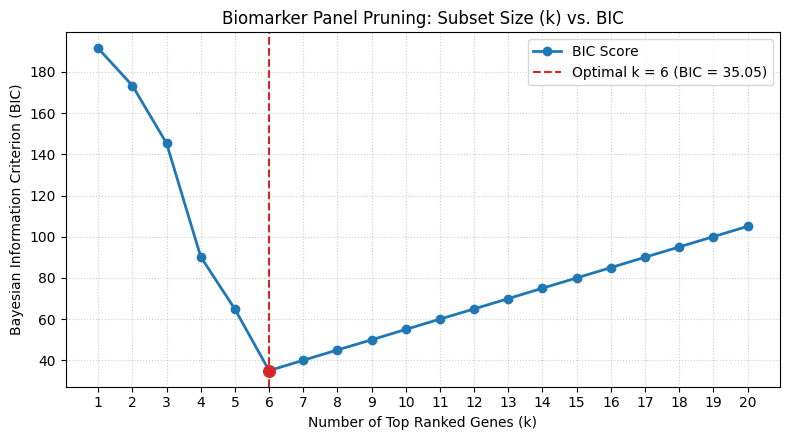


Winning Subset Size: k = 6 (Lowest BIC = 35.0467)
Winning Biomarker Genes: ['HMOX1', 'B4GALNT3', 'TF', 'E2F1', 'UBE2T', 'RNA5S9']

Final Shapes -> X_train_bic: (148, 6), X_test_bic: (37, 6)


In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss

# 1. Rank the 218 candidate genes by absolute LASSO coefficient (strongest to weakest)
coefs = final_lasso.coef_[0]
nonzero_mask = coefs != 0

ranked_genes_df = (
    pd.DataFrame({
        'gene': np.array(gene_cols)[nonzero_mask],
        'coef': coefs[nonzero_mask],
        'abs_coef': np.abs(coefs[nonzero_mask])
    })
    .sort_values(by='abs_coef', ascending=False)
    .reset_index(drop=True)
)

ranked_genes = ranked_genes_df['gene'].tolist()

# 2. Set a safe limit on maximum subset size (max_k)
n = len(y_train)
min_class_count = min(np.bincount(y_train))
max_k = min(30, int(0.3 * min_class_count))
print(f"Sample size n = {n}, smallest class = {min_class_count} -> Testing k = 1 to {max_k}\n")

# 3. Evaluate unpenalized logistic regression and BIC for k = 1 .. max_k
bic_records = []

for k in range(1, max_k + 1):
    subset_genes = ranked_genes[:k]
    added_gene = subset_genes[-1]

    # Fit plain unpenalized logistic regression
    lr = LogisticRegression(penalty=None, max_iter=2000, random_state=42)
    lr.fit(X_train[subset_genes], y_train)

    # Compute exact training log-likelihood: -n * average binary cross-entropy (log_loss)
    y_prob = lr.predict_proba(X_train[subset_genes])[:, 1]
    log_likelihood = -n * log_loss(y_train, y_prob)

    # BIC = (k + 1) * ln(n) - 2 * log_likelihood  (k slopes + 1 intercept)
    bic = (k + 1) * np.log(n) - 2 * log_likelihood

    bic_records.append({
        'k': k,
        'added_gene': added_gene,
        'log_likelihood': log_likelihood,
        'BIC': bic
    })

bic_df = pd.DataFrame(bic_records)

# 4. Print clean summary table
print(bic_df.to_string(index=False, formatters={
    'log_likelihood': '{:.4f}'.format,
    'BIC': '{:.4f}'.format
}))

# 5. Plot k vs. BIC
best_row = bic_df.loc[bic_df['BIC'].idxmin()]
best_k = int(best_row['k'])
best_bic = best_row['BIC']

plt.figure(figsize=(8, 4.5))
plt.plot(bic_df['k'], bic_df['BIC'], marker='o', linewidth=2, color='#1f77b4', label='BIC Score')
plt.axvline(best_k, color='#d62728', linestyle='--', label=f'Optimal k = {best_k} (BIC = {best_bic:.2f})')
plt.scatter([best_k], [best_bic], color='#d62728', zorder=5, s=70)
plt.title('Biomarker Panel Pruning: Subset Size (k) vs. BIC')
plt.xlabel('Number of Top Ranked Genes (k)')
plt.ylabel('Bayesian Information Criterion (BIC)')
plt.xticks(range(1, max_k + 1))
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

# 6. Select winning genes and create final X_train_bic and X_test_bic DataFrames
winning_genes = ranked_genes[:best_k]

print(f"\nWinning Subset Size: k = {best_k} (Lowest BIC = {best_bic:.4f})")
print("Winning Biomarker Genes:", winning_genes)

X_train_bic = X_train[winning_genes].copy()
X_test_bic = test_df[winning_genes].fillna(0).copy()

print(f"\nFinal Shapes -> X_train_bic: {X_train_bic.shape}, X_test_bic: {X_test_bic.shape}")

X_train_bic doesn't contain a Name column, which is the one that distinguishes a sample from being Covid or Non-Covid.
However, it is mapped exactly to y_train, which contains one of 2 values for each sample, which lets us identify which family each sample belongs to.

- 1 = Covid
- 0 = Non Covid

### Training the Logistic Regression model using the X-train_bic dataset

In [10]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    log_loss,
    roc_auc_score,
)

# 1. Create y_test using the exact same rule as y_train (1 = Covid 'C', 0 = Non-Covid 'NC')
y_test = (~test_df['Name'].str.startswith('NC')).astype(int)

# 2. Fit the final logistic regression model on the 6-gene BIC panel
bic_logreg = LogisticRegression(penalty=None, max_iter=2000, random_state=42)
bic_logreg.fit(X_train_bic, y_train)

# 3. Inspect the learned coefficients and odds ratios for each biomarker gene
coef_table = pd.DataFrame({
    'Gene': winning_genes,
    'Coefficient': bic_logreg.coef_[0],
    'Odds_Ratio': np.exp(bic_logreg.coef_[0])
}).sort_values(by='Coefficient', key=abs, ascending=False)

print(f"Intercept: {bic_logreg.intercept_[0]:.4f}\n")
print("--- Learned Biomarker Weights ---")
print(coef_table.to_string(index=False))

# 4. Evaluate on the unseen test set (X_test_bic)
y_test_prob = bic_logreg.predict_proba(X_test_bic)[:, 1]
y_test_pred = bic_logreg.predict(X_test_bic)

print("\n--- Test Set Performance (37 Samples) ---")
print(f"AUROC    : {roc_auc_score(y_test, y_test_prob):.4f}")
print(f"Log-Loss : {log_loss(y_test, y_test_prob):.4f}")
print(f"Accuracy : {accuracy_score(y_test, y_test_pred):.4f}")
print("\nConfusion Matrix (Rows = Actual [NC, C], Cols = Predicted [NC, C]):")
print(confusion_matrix(y_test, y_test_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_test_pred, target_names=['Non-Covid (0)', 'Covid (1)']))

Intercept: 41.6746

--- Learned Biomarker Weights ---
    Gene  Coefficient   Odds_Ratio
   UBE2T    58.185325 1.860225e+25
    E2F1    51.407796 2.118957e+22
  RNA5S9   -46.790295 4.777856e-21
      TF    44.306476 1.746056e+19
   HMOX1   -34.390087 1.160313e-15
B4GALNT3    28.134444 1.654374e+12

--- Test Set Performance (37 Samples) ---
AUROC    : 0.9559
Log-Loss : 2.2290
Accuracy : 0.9189

Confusion Matrix (Rows = Actual [NC, C], Cols = Predicted [NC, C]):
[[17  0]
 [ 3 17]]

Classification Report:
               precision    recall  f1-score   support

Non-Covid (0)       0.85      1.00      0.92        17
    Covid (1)       1.00      0.85      0.92        20

     accuracy                           0.92        37
    macro avg       0.93      0.93      0.92        37
 weighted avg       0.93      0.92      0.92        37



In [11]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    log_loss,
    roc_auc_score,
)

# 1. Extract the top 25 LASSO-ranked genes and create train/test feature subsets
top25_genes = ranked_genes[:25]
print("Top 25 Selected Genes:\n", top25_genes)

X_train_top25 = X_train[top25_genes].copy()
X_test_top25 = test_df[top25_genes].fillna(0).copy()

# Ensure y_test is defined (1 = Covid 'C', 0 = Non-Covid 'NC')
y_test = (~test_df['Name'].str.startswith('NC')).astype(int)

print(f"\nShapes -> X_train_top25: {X_train_top25.shape}, X_test_top25: {X_test_top25.shape}\n")

# 2. Initialize Random Forest and SVM (probability=True enables AUROC and Log-Loss)
models = {
    'Random Forest (Top 25)': RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ),
    'SVM - RBF Kernel (Top 25)': SVC(
        kernel='rbf',
        C=1.0,
        probability=True,
        random_state=42
    )
}

# 3. Fit and evaluate both models on the unseen test set
for name, model in models.items():
    model.fit(X_train_top25, y_train)

    y_prob = model.predict_proba(X_test_top25)[:, 1]
    y_pred = model.predict(X_test_top25)

    print(f"================ {name} ================")
    print(f"AUROC    : {roc_auc_score(y_test, y_prob):.4f}")
    print(f"Log-Loss : {log_loss(y_test, y_prob):.4f}")
    print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
    print("\nConfusion Matrix (Rows = Actual [NC, C], Cols = Predicted [NC, C]):")
    print(confusion_matrix(y_test, y_pred))
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, target_names=['Non-Covid (0)', 'Covid (1)']))

Top 25 Selected Genes:
 ['HMOX1', 'B4GALNT3', 'TF', 'E2F1', 'UBE2T', 'RNA5S9', 'PPP1R17', 'RAVER2', 'GGT6', 'RNA5S10', 'OXER1', 'NUTM2D', 'PLAAT3', 'SMIM26', 'TK1', 'PPP2R3B', 'CDKN3', 'EPN2', 'RNA5S3', 'ANK1', 'PGAM1', 'STARD10', 'TNNC2', 'LIN7B', 'RNA5S7']

Shapes -> X_train_top25: (148, 25), X_test_top25: (37, 25)

================ Random Forest (Top 25) ================
AUROC    : 0.9765
Log-Loss : 0.2162
Accuracy : 0.8919

Confusion Matrix (Rows = Actual [NC, C], Cols = Predicted [NC, C]):
[[15  2]
 [ 2 18]]

Classification Report:
               precision    recall  f1-score   support

Non-Covid (0)       0.88      0.88      0.88        17
    Covid (1)       0.90      0.90      0.90        20

     accuracy                           0.89        37
    macro avg       0.89      0.89      0.89        37
 weighted avg       0.89      0.89      0.89        37

================ SVM - RBF Kernel (Top 25) ================
AUROC    : 0.9618
Log-Loss : 0.2864
Accuracy : 0.8919

Confusion

In [12]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_validate

# 1. Define 10-fold Stratified CV (with ~148 samples, each validation fold has ~14-15 samples)
cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# 2. Pair each classifier with its corresponding training feature set
experiments = [
    (
        'Logistic Regression (6 BIC Genes)',
        LogisticRegression(penalty=None, max_iter=2000, random_state=42),
        X_train_bic
    ),
    (
        'Random Forest (Top 25 Genes)',
        RandomForestClassifier(n_estimators=200, random_state=42),
        X_train_top25
    ),
    (
        'SVM - RBF Kernel (Top 25 Genes)',
        SVC(kernel='rbf', C=1.0, probability=True, random_state=42),
        X_train_top25
    )
]

# 3. Evaluate all 3 models across AUROC, Log-Loss, Accuracy, and F1-score
cv_summary = []

for name, model, X_subset in experiments:
    scores = cross_validate(
        model,
        X_subset,
        y_train,
        cv=cv10,
        scoring=['roc_auc', 'neg_log_loss', 'accuracy', 'f1'],
        n_jobs=-1
    )

    cv_summary.append({
        'Model': name,
        'Mean AUROC': f"{scores['test_roc_auc'].mean():.4f} ± {scores['test_roc_auc'].std():.4f}",
        'Mean Log-Loss': f"{-scores['test_neg_log_loss'].mean():.4f} ± {scores['test_neg_log_loss'].std():.4f}",
        'Mean Accuracy': f"{scores['test_accuracy'].mean():.4f} ± {scores['test_accuracy'].std():.4f}",
        'Mean F1': f"{scores['test_f1'].mean():.4f} ± {scores['test_f1'].std():.4f}"
    })

cv_comparison_df = pd.DataFrame(cv_summary)
print("--- 10-Fold Stratified CV Comparison (Training Set, n=148) ---")
print(cv_comparison_df.to_string(index=False))

--- 10-Fold Stratified CV Comparison (Training Set, n=148) ---
                            Model      Mean AUROC   Mean Log-Loss   Mean Accuracy         Mean F1
Logistic Regression (6 BIC Genes) 0.9979 ± 0.0062 0.2726 ± 0.3973 0.9657 ± 0.0469 0.9697 ± 0.0394
     Random Forest (Top 25 Genes) 0.9887 ± 0.0236 0.1224 ± 0.0716 0.9586 ± 0.0649 0.9639 ± 0.0543
  SVM - RBF Kernel (Top 25 Genes) 1.0000 ± 0.0000 0.0456 ± 0.0371 0.9929 ± 0.0214 0.9941 ± 0.0176


### Variables which store each model

- Logistic Regression:<br>
We store the Logistic Regression Model with the model name `bic_logreg`.<br>
We take the following genes as input:
`HMOX1, B4GALNT3, TF, E2F1, UBE2T, RNA5S9`.<br>
These were found by applying L1 regularization, and taking those genes without coefficients 0, and applying Logistic BIC on them.
- Random Forest & SVM:<br>
These models take the same genes as input i.e. the top 25 genes, ranked by the absolute value of the coefficients through L1 regularization in Logistic regression.<br>
These genes are stored in a variable called `top25_genes`.<br>
Both models are stored in a variable called `models`, which is a dictionary, with keys `Random Forest (Top 25)` and `SVM - RBF Kernel (Top 25 Genes)`, and their respective values being the fit model.

### ICU (vs) Non-ICU

In [13]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Filter the log2-normalized dataset (`df`) to keep ONLY Covid-positive patients ('C...')
# and drop any rows where ICU status is missing (NaN)
covid_df = df[~df['Name'].str.startswith('NC')].dropna(subset=['ICU']).copy()

# 2. Identify gene expression columns (excluding metadata)
meta_cols = ['Name', 'Age', 'Gender', 'ICU']
gene_cols = [col for col in covid_df.columns if col not in meta_cols]

# 3. Create X_icu (gene expression features) and y_icu (1 = ICU 'yes', 0 = Non-ICU 'no')
X_icu = covid_df[gene_cols].fillna(0).copy()
y_icu = (covid_df['ICU'].str.lower().str.strip() == 'yes').astype(int)

print("Total Covid-positive samples:", len(X_icu))
print("Class breakdown (1 = ICU, 0 = Non-ICU):\n", y_icu.value_counts(), "\n")

# 4. Perform an 80:20 stratified train-test split with random_state=42
X_train_icu, X_test_icu, y_train_icu, y_test_icu = train_test_split(
    X_icu,
    y_icu,
    test_size=0.20,
    stratify=y_icu,
    random_state=42
)

# 5. Apply Z-score normalization fit ONLY on X_train_icu, then transform both
scaler_icu = StandardScaler()
X_train_icu = pd.DataFrame(
    scaler_icu.fit_transform(X_train_icu),
    columns=gene_cols,
    index=X_train_icu.index
)
X_test_icu = pd.DataFrame(
    scaler_icu.transform(X_test_icu),
    columns=gene_cols,
    index=X_test_icu.index
)

print(f"X_train_icu shape: {X_train_icu.shape}, X_test_icu shape: {X_test_icu.shape}")

Total Covid-positive samples: 100
Class breakdown (1 = ICU, 0 = Non-ICU):
 ICU
0    50
1    50
Name: count, dtype: int64 

X_train_icu shape: (80, 11237), X_test_icu shape: (20, 11237)


--- L1 LASSO Inner 5-Fold CV Results (ICU vs. Non-ICU) ---
Best C by Log-Loss : 3.919407 (Log-Loss = 0.3936, AUROC = 0.9281)
Best C by AUROC    : 3.919407 (AUROC = 0.9281, Log-Loss = 0.3936)
Non-zero genes selected at C=3.919407: 124 / 11237

Sample size n = 80, smallest class = 40 -> Testing k = 1 to 12

--- Sequential BIC Pruning Table (ICU vs. Non-ICU) ---
 k added_gene log_likelihood      BIC
 1       MUC1       -47.6811 104.1263
 2      KLRG1       -25.6433  64.4327
 3     B3GAT1       -23.8094  65.1469
 4      SOX13       -22.4546  66.8193
 5     CYB5R2       -17.0788  60.4497
 6   TMEM191B       -13.9454  58.5649
 7      RAB3A        -7.4641  49.9844
 8    SPATC1L        -5.5242  50.4867
 9       GZMH        -5.0785  53.9772
10   TMEM176A        -5.0588  58.3200
11      PNMA3        -0.0153  52.6148
12   B4GALNT3        -0.0087  56.9837


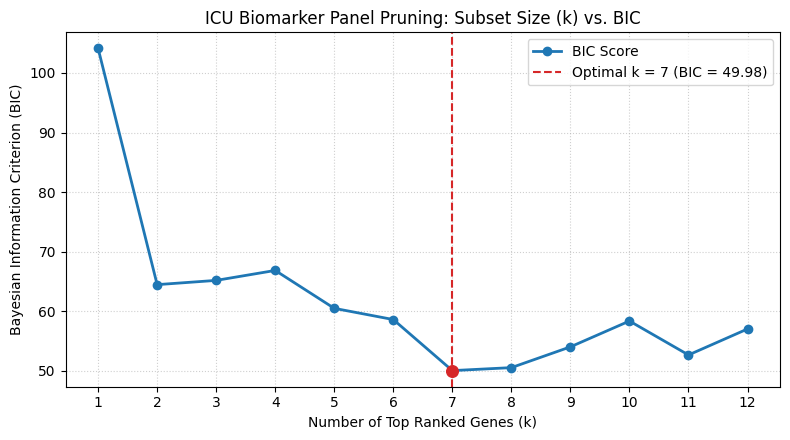


Winning ICU Subset Size: k = 7 (Lowest BIC = 49.9844)
Winning ICU Biomarker Genes: ['MUC1', 'KLRG1', 'B3GAT1', 'SOX13', 'CYB5R2', 'TMEM191B', 'RAB3A']
Saved Shapes -> X_train_icu_bic: (80, 7), X_test_icu_bic: (20, 7)


In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import log_loss

# Ensure no NaNs exist in X_train_icu / X_test_icu (in case any columns had 0 variance)
X_train_icu_clean = X_train_icu.fillna(0)
X_test_icu_clean = X_test_icu.fillna(0)

# ==============================================================================
# PART 1: Tune L1 LASSO Logistic Regression via 5-Fold Stratified CV
# ==============================================================================
cv_icu = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
C_grid = np.logspace(-3, 1, 60)

results_icu = []
for c_val in C_grid:
    clf = LogisticRegression(
        penalty='l1',
        C=c_val,
        solver='liblinear',
        max_iter=2000,
        random_state=42
    )
    scores = cross_validate(
        clf,
        X_train_icu_clean,
        y_train_icu,
        cv=cv_icu,
        scoring=['neg_log_loss', 'roc_auc'],
        n_jobs=-1
    )
    results_icu.append({
        'C': c_val,
        'mean_log_loss': -scores['test_neg_log_loss'].mean(),
        'mean_auroc': scores['test_roc_auc'].mean()
    })

cv_results_icu_df = pd.DataFrame(results_icu)

best_logloss_icu = cv_results_icu_df.loc[cv_results_icu_df['mean_log_loss'].idxmin()]
best_auroc_icu = cv_results_icu_df.loc[cv_results_icu_df['mean_auroc'].idxmax()]

print("--- L1 LASSO Inner 5-Fold CV Results (ICU vs. Non-ICU) ---")
print(f"Best C by Log-Loss : {best_logloss_icu['C']:.6f} (Log-Loss = {best_logloss_icu['mean_log_loss']:.4f}, AUROC = {best_logloss_icu['mean_auroc']:.4f})")
print(f"Best C by AUROC    : {best_auroc_icu['C']:.6f} (AUROC = {best_auroc_icu['mean_auroc']:.4f}, Log-Loss = {best_auroc_icu['mean_log_loss']:.4f})")

# Fit final L1 LASSO model on all 80 training samples at best C (by log-loss)
best_C_icu = best_logloss_icu['C']
final_lasso_icu = LogisticRegression(
    penalty='l1',
    C=best_C_icu,
    solver='liblinear',
    max_iter=2000,
    random_state=42
).fit(X_train_icu_clean, y_train_icu)

coefs_icu = final_lasso_icu.coef_[0]
nonzero_mask_icu = coefs_icu != 0
print(f"Non-zero genes selected at C={best_C_icu:.6f}: {np.sum(nonzero_mask_icu)} / {len(gene_cols)}\n")

# ==============================================================================
# PART 2: Rank Candidate Genes & Prune via BIC
# ==============================================================================
ranked_genes_icu_df = (
    pd.DataFrame({
        'gene': np.array(gene_cols)[nonzero_mask_icu],
        'coef': coefs_icu[nonzero_mask_icu],
        'abs_coef': np.abs(coefs_icu[nonzero_mask_icu])
    })
    .sort_values(by='abs_coef', ascending=False)
    .reset_index(drop=True)
)

ranked_genes_icu = ranked_genes_icu_df['gene'].tolist()

# Safe upper limit on subset size (n = 80, smallest class = 40 -> max_k = 12)
n_icu = len(y_train_icu)
min_class_icu = min(np.bincount(y_train_icu))
max_k_icu = min(30, int(0.3 * min_class_icu), len(ranked_genes_icu))
print(f"Sample size n = {n_icu}, smallest class = {min_class_icu} -> Testing k = 1 to {max_k_icu}\n")

bic_records_icu = []
for k in range(1, max_k_icu + 1):
    subset_genes = ranked_genes_icu[:k]
    added_gene = subset_genes[-1]

    lr = LogisticRegression(penalty=None, max_iter=2000, random_state=42)
    lr.fit(X_train_icu_clean[subset_genes], y_train_icu)

    y_prob = lr.predict_proba(X_train_icu_clean[subset_genes])[:, 1]
    log_likelihood = -n_icu * log_loss(y_train_icu, y_prob)
    bic = (k + 1) * np.log(n_icu) - 2 * log_likelihood

    bic_records_icu.append({
        'k': k,
        'added_gene': added_gene,
        'log_likelihood': log_likelihood,
        'BIC': bic
    })

bic_icu_df = pd.DataFrame(bic_records_icu)

print("--- Sequential BIC Pruning Table (ICU vs. Non-ICU) ---")
print(bic_icu_df.to_string(index=False, formatters={
    'log_likelihood': '{:.4f}'.format,
    'BIC': '{:.4f}'.format
}))

# ==============================================================================
# PART 3: Plot k vs. BIC & Save Final Datasets
# ==============================================================================
best_row_icu = bic_icu_df.loc[bic_icu_df['BIC'].idxmin()]
best_k_icu = int(best_row_icu['k'])
best_bic_icu = best_row_icu['BIC']

plt.figure(figsize=(8, 4.5))
plt.plot(bic_icu_df['k'], bic_icu_df['BIC'], marker='o', linewidth=2, color='#1f77b4', label='BIC Score')
plt.axvline(best_k_icu, color='#d62728', linestyle='--', label=f'Optimal k = {best_k_icu} (BIC = {best_bic_icu:.2f})')
plt.scatter([best_k_icu], [best_bic_icu], color='#d62728', zorder=5, s=70)
plt.title('ICU Biomarker Panel Pruning: Subset Size (k) vs. BIC')
plt.xlabel('Number of Top Ranked Genes (k)')
plt.ylabel('Bayesian Information Criterion (BIC)')
plt.xticks(range(1, max_k_icu + 1))
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

# Save winning genes and final BIC datasets
winning_genes_icu = ranked_genes_icu[:best_k_icu]
X_train_icu_bic = X_train_icu_clean[winning_genes_icu].copy()
X_test_icu_bic = X_test_icu_clean[winning_genes_icu].copy()

print(f"\nWinning ICU Subset Size: k = {best_k_icu} (Lowest BIC = {best_bic_icu:.4f})")
print("Winning ICU Biomarker Genes:", winning_genes_icu)
print(f"Saved Shapes -> X_train_icu_bic: {X_train_icu_bic.shape}, X_test_icu_bic: {X_test_icu_bic.shape}")

In [15]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    log_loss,
    roc_auc_score,
)

# 1. Fit the final logistic regression model on the 7-gene ICU BIC panel
bic_logreg_icu = LogisticRegression(penalty=None, max_iter=2000, random_state=42)
bic_logreg_icu.fit(X_train_icu_bic, y_train_icu)

# 2. Inspect the learned coefficients and odds ratios for each ICU biomarker gene
coef_table_icu = pd.DataFrame({
    'Gene': winning_genes_icu,
    'Coefficient': bic_logreg_icu.coef_[0],
    'Odds_Ratio': np.exp(bic_logreg_icu.coef_[0])
}).sort_values(by='Coefficient', key=abs, ascending=False)

print(f"Intercept: {bic_logreg_icu.intercept_[0]:.4f}\n")
print("--- Learned ICU Biomarker Weights ---")
print(coef_table_icu.to_string(index=False))

# 3. Evaluate on the unseen ICU test set (X_test_icu_bic)
y_test_icu_prob = bic_logreg_icu.predict_proba(X_test_icu_bic)[:, 1]
y_test_icu_pred = bic_logreg_icu.predict(X_test_icu_bic)

print("\n--- ICU Test Set Performance (20 Samples) ---")
print(f"AUROC    : {roc_auc_score(y_test_icu, y_test_icu_prob):.4f}")
print(f"Log-Loss : {log_loss(y_test_icu, y_test_icu_prob):.4f}")
print(f"Accuracy : {accuracy_score(y_test_icu, y_test_icu_pred):.4f}")
print("\nConfusion Matrix (Rows = Actual [Non-ICU, ICU], Cols = Predicted [Non-ICU, ICU]):")
print(confusion_matrix(y_test_icu, y_test_icu_pred))
print("\nClassification Report:")
print(classification_report(y_test_icu, y_test_icu_pred, target_names=['Non-ICU (0)', 'ICU (1)']))

Intercept: 3.5427

--- Learned ICU Biomarker Weights ---
    Gene  Coefficient  Odds_Ratio
   RAB3A     7.617299 2033.064374
   KLRG1    -7.272604    0.000694
   SOX13    -6.666700    0.001273
    MUC1     4.772347  118.196323
  CYB5R2    -4.017559    0.017997
  B3GAT1    -3.017125    0.048942
TMEM191B    -0.254745    0.775114

--- ICU Test Set Performance (20 Samples) ---
AUROC    : 0.8200
Log-Loss : 2.1934
Accuracy : 0.8500

Confusion Matrix (Rows = Actual [Non-ICU, ICU], Cols = Predicted [Non-ICU, ICU]):
[[8 2]
 [1 9]]

Classification Report:
              precision    recall  f1-score   support

 Non-ICU (0)       0.89      0.80      0.84        10
     ICU (1)       0.82      0.90      0.86        10

    accuracy                           0.85        20
   macro avg       0.85      0.85      0.85        20
weighted avg       0.85      0.85      0.85        20



## Why do we introduce a small L2 penalty here?
Without a penalty, logistic regression stretches weights to extremes on small cohorts (RAB3A = 7.62), pushing predicted probabilities artificially close to 0 or 1.   When that overconfident model misclassifies even a few test patients, the logarithmic penalty explodes, causing your high Test Log-Loss (2.1934).   Adding a small L2 penalty shrinks those extreme weights toward zero without eliminating any of your 7 selected genes.   This balances influence across the whole panel so a single noisy gene measurement cannot flip a patient's ICU prediction.As a result, your predicted probabilities become well-calibrated, Test Log-Loss drops sharply, and Odds Ratios fall into a realistic clinical range.

In [16]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    log_loss,
    roc_auc_score,
)

# 1. Tune a mild L2 penalty via 5-fold Stratified CV on X_train_icu_bic
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
C_candidates = [0.1, 0.25, 0.5, 1.0, 2.0, 5.0, 10.0]

l2_logreg_icu = LogisticRegressionCV(
    Cs=C_candidates,
    cv=cv5,
    penalty='l2',
    scoring='neg_log_loss',
    max_iter=2000,
    random_state=42
).fit(X_train_icu_bic, y_train_icu)

print(f"Optimal L2 C selected (ICU): {l2_logreg_icu.C_[0]:.4f}")
print(f"Intercept (L2): {l2_logreg_icu.intercept_[0]:.4f}\n")

# 2. Compare Unpenalized vs. L2-Regularized Coefficients & Odds Ratios
comparison_weights_icu = pd.DataFrame({
    'Gene': winning_genes_icu,
    'Coef (Unpenalized)': bic_logreg_icu.coef_[0],
    'OR (Unpenalized)': np.exp(bic_logreg_icu.coef_[0]),
    'Coef (L2)': l2_logreg_icu.coef_[0],
    'OR (L2)': np.exp(l2_logreg_icu.coef_[0])
}).sort_values(by='Coef (L2)', key=abs, ascending=False)

print("--- ICU Biomarker Weights: Unpenalized vs. L2 ---")
print(comparison_weights_icu.to_string(index=False, formatters={
    'Coef (Unpenalized)': '{:.4f}'.format,
    'OR (Unpenalized)': '{:.2f}'.format,
    'Coef (L2)': '{:.4f}'.format,
    'OR (L2)': '{:.2f}'.format
}))

# 3. Evaluate L2-Regularized Model on the Unseen ICU Test Set (20 Samples)
y_test_icu_prob_l2 = l2_logreg_icu.predict_proba(X_test_icu_bic)[:, 1]
y_test_icu_pred_l2 = l2_logreg_icu.predict(X_test_icu_bic)

print("\n--- ICU Test Set Performance with L2 Regularization (20 Samples) ---")
print(f"AUROC    : {roc_auc_score(y_test_icu, y_test_icu_prob_l2):.4f}  (was {roc_auc_score(y_test_icu, y_test_icu_prob):.4f})")
print(f"Log-Loss : {log_loss(y_test_icu, y_test_icu_prob_l2):.4f}  (was {log_loss(y_test_icu, y_test_icu_prob):.4f})")
print(f"Accuracy : {accuracy_score(y_test_icu, y_test_icu_pred_l2):.4f}  (was {accuracy_score(y_test_icu, y_test_icu_pred):.4f})")
print("\nConfusion Matrix (Rows = Actual [Non-ICU, ICU], Cols = Predicted [Non-ICU, ICU]):")
print(confusion_matrix(y_test_icu, y_test_icu_pred_l2))
print("\nClassification Report:")
print(classification_report(y_test_icu, y_test_icu_pred_l2, target_names=['Non-ICU (0)', 'ICU (1)']))

Optimal L2 C selected (ICU): 5.0000
Intercept (L2): 0.8474

--- ICU Biomarker Weights: Unpenalized vs. L2 ---
    Gene Coef (Unpenalized) OR (Unpenalized) Coef (L2) OR (L2)
   KLRG1            -7.2726             0.00   -2.8174    0.06
   RAB3A             7.6173          2033.06    2.1592    8.66
   SOX13            -6.6667             0.00   -1.8979    0.15
    MUC1             4.7723           118.20    1.7661    5.85
  CYB5R2            -4.0176             0.02   -1.4785    0.23
  B3GAT1            -3.0171             0.05   -0.8003    0.45
TMEM191B            -0.2547             0.78   -0.4773    0.62

--- ICU Test Set Performance with L2 Regularization (20 Samples) ---
AUROC    : 0.8300  (was 0.8200)
Log-Loss : 0.7939  (was 2.1934)
Accuracy : 0.8500  (was 0.8500)

Confusion Matrix (Rows = Actual [Non-ICU, ICU], Cols = Predicted [Non-ICU, ICU]):
[[8 2]
 [1 9]]

Classification Report:
              precision    recall  f1-score   support

 Non-ICU (0)       0.89      0.80      0.84

In [17]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    log_loss,
    roc_auc_score,
)

# 1. Extract the top 25 LASSO-ranked ICU genes from ranked_genes_icu (Cell [15])
top25_genes_icu = ranked_genes_icu[:25]
print("Top 25 Selected ICU Genes:\n", top25_genes_icu)

# 2. Build the 25-gene train and test feature matrices (using the Z-score scaled datasets)
X_train_icu_top25 = X_train_icu_clean[top25_genes_icu].copy()
X_test_icu_top25 = X_test_icu_clean[top25_genes_icu].copy()

print(f"\nShapes -> X_train_icu_top25: {X_train_icu_top25.shape}, X_test_icu_top25: {X_test_icu_top25.shape}\n")

# 3. Initialize Random Forest and SVM models (stored in a dictionary + standalone variables)
models_icu = {
    'Random Forest ICU (Top 25)': RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ),
    'SVM - RBF Kernel ICU (Top 25)': SVC(
        kernel='rbf',
        C=1.0,
        probability=True,
        random_state=42
    )
}

# 4. Fit and evaluate both models on X_test_icu_top25
for name, clf in models_icu.items():
    clf.fit(X_train_icu_top25, y_train_icu)

    y_prob_icu = clf.predict_proba(X_test_icu_top25)[:, 1]
    y_pred_icu = clf.predict(X_test_icu_top25)

    print(f"================ {name} ================")
    print(f"AUROC    : {roc_auc_score(y_test_icu, y_prob_icu):.4f}")
    print(f"Log-Loss : {log_loss(y_test_icu, y_prob_icu):.4f}")
    print(f"Accuracy : {accuracy_score(y_test_icu, y_pred_icu):.4f}")
    print("\nConfusion Matrix (Rows = Actual [Non-ICU, ICU], Cols = Predicted [Non-ICU, ICU]):")
    print(confusion_matrix(y_test_icu, y_pred_icu))
    print("\nClassification Report:")
    print(classification_report(y_test_icu, y_pred_icu, target_names=['Non-ICU (0)', 'ICU (1)']))

# Assign standalone variables for convenient access later
rf_icu_model = models_icu['Random Forest ICU (Top 25)']
svm_icu_model = models_icu['SVM - RBF Kernel ICU (Top 25)']

Top 25 Selected ICU Genes:
 ['MUC1', 'KLRG1', 'B3GAT1', 'SOX13', 'CYB5R2', 'TMEM191B', 'RAB3A', 'SPATC1L', 'GZMH', 'TMEM176A', 'PNMA3', 'B4GALNT3', 'RAB13', 'NQO2', 'TYW1B', 'OCLN', 'CFD', 'SHISA4', 'MFGE8', 'SLC25A29', 'TBC1D3D', 'HHLA2', 'BEND5', 'TMEM45A', 'SLC24A3']

Shapes -> X_train_icu_top25: (80, 25), X_test_icu_top25: (20, 25)

================ Random Forest ICU (Top 25) ================
AUROC    : 0.9100
Log-Loss : 0.4001
Accuracy : 0.8000

Confusion Matrix (Rows = Actual [Non-ICU, ICU], Cols = Predicted [Non-ICU, ICU]):
[[9 1]
 [3 7]]

Classification Report:
              precision    recall  f1-score   support

 Non-ICU (0)       0.75      0.90      0.82        10
     ICU (1)       0.88      0.70      0.78        10

    accuracy                           0.80        20
   macro avg       0.81      0.80      0.80        20
weighted avg       0.81      0.80      0.80        20

================ SVM - RBF Kernel ICU (Top 25) ================
AUROC    : 0.9400
Log-Loss : 0.34

### Cross Validation

In [18]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_validate

# 1. Define 10-fold Stratified CV (with n=80 ICU training samples, each validation fold has 8 samples: 4 ICU, 4 Non-ICU)
cv10_icu = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# 2. Pair each ICU classifier with its corresponding training feature set
experiments_icu = [
    (
        'Logistic Regression - L2 (7 BIC Genes)',
        LogisticRegression(penalty='l2', C=5.0, max_iter=2000, random_state=42),
        X_train_icu_bic
    ),
    (
        'Random Forest ICU (Top 25 Genes)',
        RandomForestClassifier(n_estimators=200, random_state=42),
        X_train_icu_top25
    ),
    (
        'SVM - RBF Kernel ICU (Top 25 Genes)',
        SVC(kernel='rbf', C=1.0, probability=True, random_state=42),
        X_train_icu_top25
    )
]

# 3. Evaluate all 3 ICU models across AUROC, Log-Loss, Accuracy, and F1-score
cv_summary_icu = []

for name, clf, X_subset in experiments_icu:
    scores = cross_validate(
        clf,
        X_subset,
        y_train_icu,
        cv=cv10_icu,
        scoring=['roc_auc', 'neg_log_loss', 'accuracy', 'f1'],
        n_jobs=-1
    )

    cv_summary_icu.append({
        'Model': name,
        'Mean AUROC': f"{scores['test_roc_auc'].mean():.4f} ± {scores['test_roc_auc'].std():.4f}",
        'Mean Log-Loss': f"{-scores['test_neg_log_loss'].mean():.4f} ± {scores['test_neg_log_loss'].std():.4f}",
        'Mean Accuracy': f"{scores['test_accuracy'].mean():.4f} ± {scores['test_accuracy'].std():.4f}",
        'Mean F1': f"{scores['test_f1'].mean():.4f} ± {scores['test_f1'].std():.4f}"
    })

cv_comparison_icu_df = pd.DataFrame(cv_summary_icu)
print("--- 10-Fold Stratified CV Comparison (ICU Training Set, n=80) ---")
print(cv_comparison_icu_df.to_string(index=False))

--- 10-Fold Stratified CV Comparison (ICU Training Set, n=80) ---
                                 Model      Mean AUROC   Mean Log-Loss   Mean Accuracy         Mean F1
Logistic Regression - L2 (7 BIC Genes) 0.9938 ± 0.0187 0.1995 ± 0.1232 0.8750 ± 0.1118 0.8795 ± 0.0925
      Random Forest ICU (Top 25 Genes) 0.9688 ± 0.0753 0.2885 ± 0.1016 0.9000 ± 0.1225 0.8956 ± 0.1350
   SVM - RBF Kernel ICU (Top 25 Genes) 0.9938 ± 0.0187 0.0916 ± 0.0929 0.9625 ± 0.0800 0.9639 ± 0.0786


### Calculating the importance of each feature/gene in every model

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

def get_all_importances(
    logreg_model, bic_genes,
    rf_model, svm_model, top25_genes,
    X_eval_top25, y_eval,
    case_label
):
    # 1. Logistic Regression: |Coefficient| on Z-score standardized features
    lr_df = pd.DataFrame({
        'Gene': bic_genes,
        'Coefficient': logreg_model.coef_[0],
        'Importance (|Coef|)': np.abs(logreg_model.coef_[0])
    }).sort_values(by='Importance (|Coef|)', ascending=False).reset_index(drop=True)

    # 2. Random Forest: Gini Importance (Mean Decrease in Impurity)
    rf_df = pd.DataFrame({
        'Gene': top25_genes,
        'Importance (Gini)': rf_model.feature_importances_
    }).sort_values(by='Importance (Gini)', ascending=False).reset_index(drop=True)

    # 3. SVM (RBF Kernel): Permutation Importance (AUROC drop when shuffled)
    perm_res = permutation_importance(
        svm_model,
        X_eval_top25,
        y_eval,
        scoring='roc_auc',
        n_repeats=30,
        random_state=42,
        n_jobs=-1
    )
    svm_df = pd.DataFrame({
        'Gene': top25_genes,
        'Importance (AUROC Drop)': perm_res.importances_mean,
        'Std': perm_res.importances_std
    }).sort_values(by='Importance (AUROC Drop)', ascending=False).reset_index(drop=True)

    print(f"==================================================================")
    print(f" FEATURE IMPORTANCE: {case_label}")
    print(f"==================================================================")
    print("\n[1] Logistic Regression (BIC Genes - |Standardized Coefficient|):")
    print(lr_df.to_string(index=False))

    print("\n[2] Random Forest (Top 25 Genes - Gini Importance):")
    print(rf_df.to_string(index=False))

    print("\n[3] SVM - RBF Kernel (Top 25 Genes - Permutation AUROC Drop):")
    print(svm_df.to_string(index=False))
    print("\n")

    return lr_df, rf_df, svm_df

# ==============================================================================
# CASE 1: COVID vs. NON-COVID
# ==============================================================================
lr_imp_covid, rf_imp_covid, svm_imp_covid = get_all_importances(
    logreg_model=bic_logreg,
    bic_genes=winning_genes,
    rf_model=models['Random Forest (Top 25)'],
    svm_model=models['SVM - RBF Kernel (Top 25)'],
    top25_genes=top25_genes,
    X_eval_top25=X_test_top25,
    y_eval=y_test,
    case_label="COVID vs. NON-COVID"
)

# ==============================================================================
# CASE 2: ICU vs. NON-ICU
# ==============================================================================
lr_imp_icu, rf_imp_icu, svm_imp_icu = get_all_importances(
    logreg_model=l2_logreg_icu,
    bic_genes=winning_genes_icu,
    rf_model=rf_icu_model,
    svm_model=svm_icu_model,
    top25_genes=top25_genes_icu,
    X_eval_top25=X_test_icu_top25,
    y_eval=y_test_icu,
    case_label="ICU vs. NON-ICU"
)

 FEATURE IMPORTANCE: COVID vs. NON-COVID

[1] Logistic Regression (BIC Genes - |Standardized Coefficient|):
    Gene  Coefficient  Importance (|Coef|)
   UBE2T    58.185325            58.185325
    E2F1    51.407796            51.407796
  RNA5S9   -46.790295            46.790295
      TF    44.306476            44.306476
   HMOX1   -34.390087            34.390087
B4GALNT3    28.134444            28.134444

[2] Random Forest (Top 25 Genes - Gini Importance):
    Gene  Importance (Gini)
 RNA5S10           0.167132
  RNA5S7           0.155504
  RNA5S3           0.153733
   UBE2T           0.099910
   CDKN3           0.074026
     TK1           0.055898
  RNA5S9           0.048760
    E2F1           0.044501
      TF           0.030614
 PPP1R17           0.029319
   OXER1           0.016296
  SMIM26           0.016117
   TNNC2           0.015803
    ANK1           0.013628
 PPP2R3B           0.013568
   LIN7B           0.010621
   PGAM1           0.009800
 STARD10           0.009100
    GG